# Module 5 · Worksheet 1
# Introduction to Decision Trees

**ISA 591 — Introduction to Data Mining in Business**  
**Focus:** Decision rules, tree diagrams, class predictions, propensities, and regression leaves.

## Learning goals

1. Trace a customer through a tree and translate the path into an IF–THEN rule.
2. Distinguish a predicted class from the probability estimated in its terminal node.
3. Prepare customer-churn data and fit an interpretable classification tree.
4. Connect tree predictions to confusion matrices and ROC AUC.
5. Explain how a regression tree predicts a numeric outcome.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
import sklearn

SEED = 591
pd.set_option('display.max_columns', 100)
pd.set_option('display.precision', 4)
print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.5.2


## 1. A tree is a collection of rules

A **root node** contains the fitting observations. A **decision node** asks a question such as `tenure <= 12.5`. Follow the left branch when the condition is true and the right branch when it is false. A **terminal node (leaf)** supplies the prediction.

For an unweighted classification tree, the leaf's most common class gives its class prediction; its class proportions give estimated probabilities. A leaf is a group of similar cases under the rules—not a guarantee that every member has the same outcome.

### Practice 1A — Follow this hypothetical retention tree

| Rule | Customers who stayed (0) | Customers who churned (1) |
|---|---:|---:|
| `tenure <= 12` AND `Contract = Month-to-month` | 14 | 26 |
| `tenure <= 12` AND `Contract != Month-to-month` | 45 | 5 |
| `tenure > 12` | 86 | 14 |

Customer A has tenure 8 months and a month-to-month contract. Customer B has tenure 8 months and a two-year contract. Customer C has tenure 36 months and a month-to-month contract.

**Before coding:** record each customer's leaf, predicted class, and churn probability. Use the class with the larger count.

| Customer | Leaf / rule | Predicted class | Estimated P(churn) |
|---|---|---|---|
| A | | | |
| B | | | |
| C | | | |

In [ ]:
## Suppose that we are predicting y = {"Churned": 1, "Stayed": 0}

#### we have a 3-leaf decision tree (3 terminal nodes)
##### TERMINAL NODE 1: if tenure <= 12 months AND contract is month to month ---- 14 (STAYED) ---- 26 (CHURNED)
####### y_hat = 1  (most common class if the cutoff is set 0.5)  
####### p_hat = 26 / (26+14) = 0.65   

0.65

### Practice 1B — Calculate a leaf probability

Complete the probability and class prediction for Customer A.

In [ ]:
## CUSTOMER A
y_hat = 1
p_hat = 0.65 ## P(CHURN)
p_hat = 0.35 ## P(STAY)

## CUSTOMER C
y_hat = 0
p_hat = 14 / (86+14) = 0.14  ## P(CHURN)
p_hat = 86 / (86+14) = 0.86  ## P(STAY)

<details><summary>Hint</summary>

Divide the number of churners in the leaf by the total number in that leaf.

</details>

**Interpret / discuss:** Do Customers A and C have to receive the same prediction just because both have month-to-month contracts? Explain using the complete path.

**Your response:**

_Write your answer here._

## 2. Set up the business example

## Business setting: customer retention

A telecommunications company wants to identify customers who are likely to leave. Each row is one customer. **`Churn = Yes` is the positive class**, encoded as 1; `No` is encoded as 0.

| Variables | Meaning / role |
|---|---|
| `customerID` | Customer identifier; excluded from the predictor matrix. |
| `tenure` | Number of months the customer has stayed with the company. |
| `MonthlyCharges`, `TotalCharges` | Monthly charge and accumulated charges. `TotalCharges` may initially contain nonnumeric entries. |
| `Contract` | Month-to-month, one-year, or two-year contract. |
| `InternetService`, `PhoneService`, `MultipleLines` | Service types. |
| `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | Service options; some levels describe the absence of the underlying service. |
| `PaymentMethod`, `PaperlessBilling` | Payment and billing categories. |
| `gender`, `SeniorCitizen`, `Partner`, `Dependents` | Demographic and household attributes. Numeric storage does not automatically mean a continuous measurement. |
| `Churn` | Outcome, not a predictor. |

This is a classroom historical snapshot. Before deployment, confirm that every input is available at the actual prediction time and assess whether sensitive attributes are appropriate for the intended use.

### Run: load and split the data

The main application throughout this module uses the Telco customer-churn data. **TRAINING - Fitting data** grow the exploratory models; the **TEST - final test data** are held aside until the stated evaluation checkpoint.


In [5]:
## READ DATA
df = pd.read_csv('https://raw.githubusercontent.com/martinwg/ISA591/refs/heads/main/data/Telco_Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
## DROP customerId
df.drop(columns=['customerID'], inplace = True)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
## MISSING VALUES?
df.isna().sum().sum()

0

In [9]:
## Let's select gender, tenure, MonthlyCharges as predictors ---- Churn
df = df[['gender', 'tenure', 'MonthlyCharges', 'Churn']]
df.head()

,gender,tenure,MonthlyCharges,Churn
0,Female,1,29.85,No
1,Male,34,56.95,No
2,Male,2,53.85,Yes
3,Male,45,42.30,No
4,Female,2,70.70,Yes


In [10]:
## ENCODE CHURN AS 0 - 1
##### 1 (churn) b/c you want to predict p(churn)
df.Churn = df.Churn.map({"Yes": 1, "No": 0})
df.head()

,gender,tenure,MonthlyCharges,Churn
0,Female,1,29.85,0
1,Male,34,56.95,0
2,Male,2,53.85,1
3,Male,45,42.30,0
4,Female,2,70.70,1


In [11]:
## ENCODE CATEGORICAL PREDICTORS
df = pd.get_dummies(df, drop_first = True, dtype = int)
df.head()

,tenure,MonthlyCharges,Churn,gender_Male
0,1,29.85,0,0
1,34,56.95,0,1
2,2,53.85,1,1
3,45,42.30,0,1
4,2,70.70,1,0


In [12]:
## Create X and y
X = df.drop("Churn", axis = 1)
y = df.Churn

In [15]:
## SPLIT INTO TRAINING (0.8) AND TEST, RANDOM STATE = 591
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 591)

print(X_train.shape)
print(X_test.shape)

(5634, 3)
(1409, 3)


### Practice 2A — Inspect the response

Calculate the churn proportion in the development set and identify the majority class. Why is a majority-class benchmark useful?

In [17]:
y_train.value_counts()

Churn
0    4146
1    1488
Name: count, dtype: int64

In [18]:
# TODO
#### IMBALANCED?  Yes, not severely (we can proceed to model without using SMOTE)

churn_rate = y_train.mean()
majority_class = 0
print('Development churn rate:', churn_rate)
print('Majority class:', majority_class)

Development churn rate: 0.2641107561235357
Majority class: 0


## 3. Fit a small tree

For this first illustration, set the structure **before** inspecting the test results: use `max_depth=3` and `min_samples_leaf=25`. The purpose is to read the model. We will systematically tune complexity in Worksheet 3.

The `model` step is the tree; the `prep` step is its input preparation.

### Practice 3A — Construct and fit the classifier

Create a tree with `DecisionTreeClassifier(max_depth=3, min_samples_leaf=25, random_state=SEED)`. Fit it on `X_train, y_train`.

In [19]:
## tree module from sklearn
from sklearn.tree import DecisionTreeClassifier  ## y = {0,1}

## instance (we call max_depth = 3, min_samples_leaf=25 ----  hyperparameters)
## max_depth = 3, min_samples_leaf=25 are STOPPING RULES
## criterion is just the IMPURITY METRIC to minimize
dt = DecisionTreeClassifier(max_depth = 3, min_samples_leaf=25, random_state=591, criterion = "gini")

## fit
dt.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, min_samples_leaf=25, random_state=591)

### Practice 3B — Display the tree

Use the `plot_tree` function from sklearn.

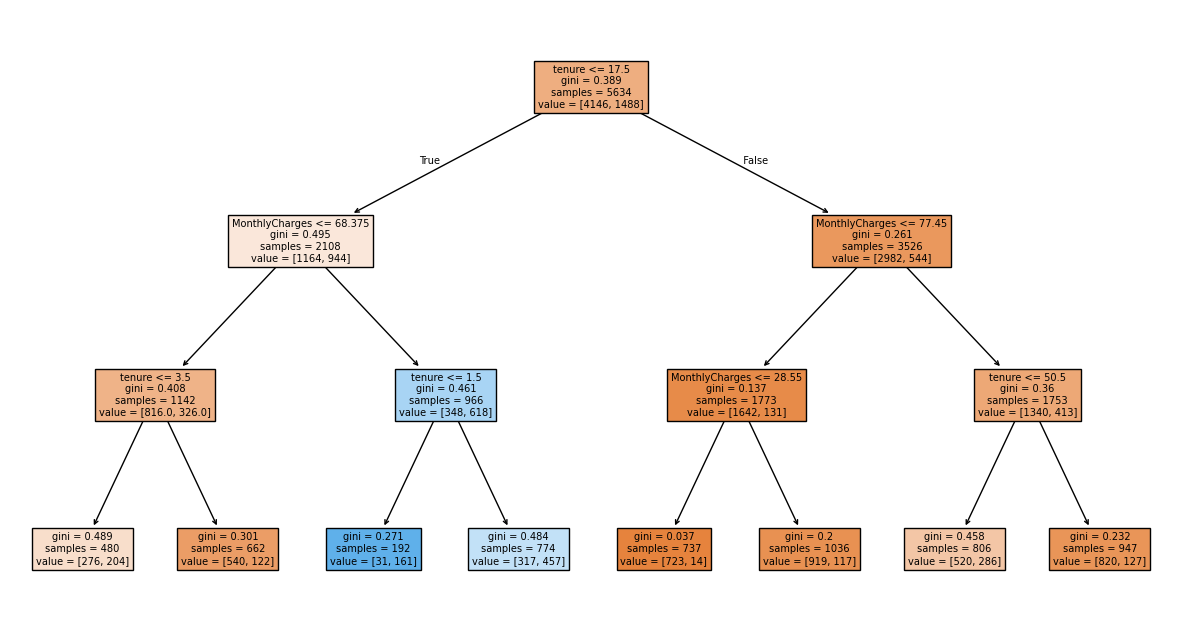

In [25]:
## DIAGRAM 
from sklearn.tree import plot_tree

plt.figure(figsize = (15,8))
plot_tree(dt, feature_names=X_train.columns, filled = True);

In [ ]:
## RULE FOR TERMINAL NODE ON THE LEFT
#### if tenure <= 17.5 months AND monthly charges <= 68.375 AND tenure <= 3.5

**Interpret / discuss:** Identify the root split. Write one full path to a leaf as an IF–THEN rule. Which part of the rule is an interaction between customer characteristics?

**Your response:**

_Write your answer here._

## 4. Decision Boundary

Use the function below to plot the decision boundary.

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def plot_decision_boundaries(X, y, model_class, **model_params):
    """
    Function to plot the decision boundaries of a classification model.
    This uses just the first two columns of the data for fitting
    the model as we need to find the predicted value for every point in
    scatter plot.
    Arguments:
            X: Feature data as a NumPy-type array.
            y: Label data as a NumPy-type array.
            model_class: A Scikit-learn ML estimator class
            e.g. GaussianNB (imported from sklearn.naive_bayes) or
            LogisticRegression (imported from sklearn.linear_model)
            **model_params: Model parameters to be passed on to the ML estimator

    Typical code example:
            plt.figure()
            plt.title("KNN decision boundary with neighbros: 5",fontsize=16)
            plot_decision_boundaries(X_train,y_train,KNeighborsClassifier,n_neighbors=5)
            plt.show()
    """
    try:
        X = np.array(X)
        y = np.array(y).flatten()
    except:
        print("Coercing input data to NumPy arrays failed")
    # Reduces to the first two columns of data
    reduced_data = X[:, :2]
    # Instantiate the model object
    model = model_class(**model_params)
    # Fits the model with the reduced data
    model.fit(reduced_data, y)

    # Step size of the mesh. Decrease to increase the quality of the VQ.
    h = .02     # point in the mesh [x_min, m_max]x[y_min, y_max].

    # Plot the decision boundary. For that, we will assign a color to each
    x_min, x_max = reduced_data[:, 0].min() - 1, reduced_data[:, 0].max() + 1
    y_min, y_max = reduced_data[:, 1].min() - 1, reduced_data[:, 1].max() + 1
    # Meshgrid creation
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

    # Obtain labels for each point in mesh using the model.
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                         np.arange(y_min, y_max, 0.1))

    # Predictions to obtain the classification results
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    # Plotting
    plt.contourf(xx, yy, Z, alpha=0.4,cmap=plt.cm.Greys)
    plt.scatter(X[:, 0], X[:, 1], c=y, alpha=0.8)
    plt.xlabel("Feature-1",fontsize=15)
    plt.ylabel("Feature-2",fontsize=15)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    return plt

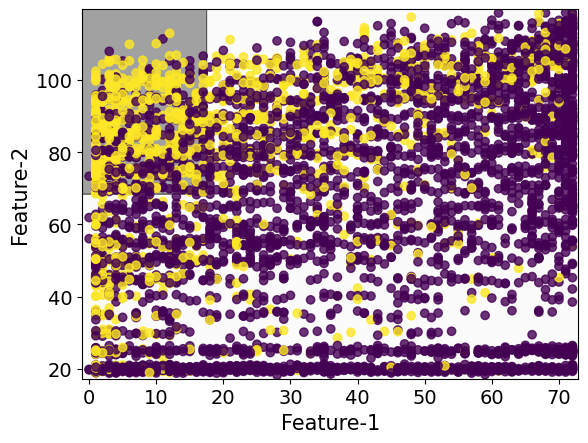

In [21]:
# plot the decision boundary of the classifier
plot_decision_boundaries(X_train, y_train, DecisionTreeClassifier, max_depth=3, min_samples_leaf=25, random_state=SEED);

### Practice 4A — Match the model probability

compare the first obs of the test set with the output of the `predict_proba()`.

**Interpret / discuss:** Why do two customers reaching the same leaf get the same propensity, even when some of their original predictor values differ?

**Your response:**

_Write your answer here._

## 5. Evaluate the pre-specified tree

### Run: evaluation helpers from Module 4

The functions below report class-based metrics, ROC AUC from probabilities, and top-group lift. All comparisons in a table must use the same observations and the same positive class.

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, mean_squared_error, mean_absolute_error
)

def classification_metrics(model, frame, truth):
    predicted = model.predict(frame)
    tn, fp, fn, tp = confusion_matrix(truth, predicted, labels=[0, 1]).ravel()
    return {
        'Accuracy': accuracy_score(truth, predicted),
        'Recall': recall_score(truth, predicted, zero_division=0),
        'Specificity': tn / (tn + fp),
        'Precision': precision_score(truth, predicted, zero_division=0),
        'F1': f1_score(truth, predicted, zero_division=0),
        'ROC AUC': roc_auc_score(truth, probabilities)
    }

def targeting_metrics(truth, probabilities, fraction=0.20):
    """Select exactly the top k; ties retain the existing row order."""
    truth = np.asarray(truth)
    probabilities = np.asarray(probabilities)
    k = max(1, int(np.ceil(fraction * len(truth))))
    selected = np.argsort(-probabilities, kind='stable')[:k]
    rate = truth[selected].mean()
    base_rate = truth.mean()
    return {
        'Selected': k,
        'Churners captured': int(truth[selected].sum()),
        'Selected churn rate': rate,
        'Capture rate': truth[selected].sum() / truth.sum(),
        'Lift': rate / base_rate
    }

### Run: compare with a majority-class benchmark

In [ ]:
from sklearn.dummy import DummyClassifier

benchmark = DummyClassifier(strategy='most_frequent')
benchmark.fit(X_train, y_train)
results = pd.DataFrame({
    'Majority benchmark': classification_metrics(benchmark, X_test, y_test),
    'Depth-3 tree': classification_metrics(dt, X_test, y_test)
}).T
display(results)
ConfusionMatrixDisplay.from_estimator(
    dt, X_test, y_test, labels=[0, 1], display_labels=['Stayed', 'Churned']
)
plt.title('Final test confusion matrix: pre-specified tree')
plt.show()

**Interpret / discuss:** Does the tree improve on the benchmark for both accuracy and recall? Explain a false positive and a false negative in this retention setting.

**Your response:**

_Write your answer here._

## 6. Regression trees: a different leaf prediction

For a regression tree using **squared error**, the leaf predicts the average numeric response among its fitting observations.

The following small **synthetic** example predicts next-month spending from tenure. It illustrates the calculation, not a fitted business forecast from the Telco file.

In [ ]:
from sklearn.tree import DecisionTreeRegressor
sales = pd.DataFrame({
    'TenureMonths': [2, 4, 6, 8, 18, 24, 30, 36],
    'NextMonthSpend': [40, 44, 49, 47, 88, 94, 101, 97]
})
reg_tree = DecisionTreeRegressor(max_depth=1, random_state=SEED)
reg_tree.fit(sales[['TenureMonths']], sales['NextMonthSpend'])
plt.figure(figsize=(10, 5))
plot_tree(reg_tree, feature_names=['TenureMonths'], filled=False,
          rounded=True, precision=2)
plt.title('Synthetic spending example: regression stump')
plt.show()

## Exit ticket

In three sentences, explain: (1) how a tree assigns a customer to a leaf; (2) the difference between a predicted class and a propensity; and (3) how a squared-error regression tree makes a prediction.

**Your response:**

_Write your answer here._

## Implementation references

These official references support the API details and the explicitly labeled implementation notes. The questions and small constructed examples are classroom exercises.

- [Decision trees: concepts and implementation](https://scikit-learn.org/stable/modules/tree.html)
- [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)
- [DecisionTreeRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html)

